# Homework8 Jiayan Wang

## Numerical Solution of the Differential Equations

We consider the coupled system

$$
\begin{aligned}
\frac{dR}{dt} &= \frac{k}{1+I^n}-\delta R,\\
\frac{d\lambda}{dt} &= \frac{k}{1+R^n}-\delta\lambda,\\
\frac{dI}{dt} &= \frac{k}{1+\lambda^n}-\delta I.
\end{aligned}
$$

Because the equations are nonlinear and coupled, we solve them numerically.
Define the state vector

$$
\mathbf{y}(t)=
\begin{pmatrix}R(t)\\ \lambda(t)\\ I(t)\end{pmatrix}.
$$

The system can then be written as

$$
\frac{d\mathbf{y}}{dt}=\mathbf{f}(\mathbf{y}),
$$

where $\mathbf{f}$ contains the three right-hand sides above.

Starting from a specified initial state, the solution advances according to

$$
\mathbf{y}(t+h)
=
\mathbf{y}(t)
+
\int_t^{t+h}\mathbf{f}(\mathbf{y}(s))\,ds.
$$

We approximate this integral using DOP853, an adaptive Runge–Kutta method
implemented in `scipy.integrate.solve_ivp`. At each step, the method evaluates
the derivatives at several intermediate states and combines them to estimate
the next state. It adjusts the step size to control the numerical error.
All three variables are integrated together because their rates depend on
one another.

We use

$$
k=10,\qquad \delta=0.5,\qquad n=3,
$$

with initial conditions

$$
(R(0),\lambda(0),I(0))=(0.1,1,2).
$$

The numerical solution below shows sustained oscillations: after the initial
transient, the three concentrations repeatedly rise and fall with phase
differences and approximately constant amplitudes.

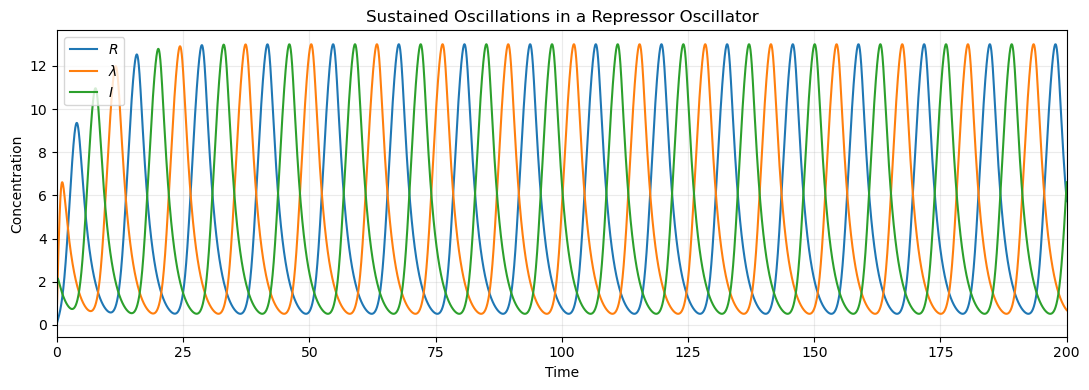

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Parameters
k = 10.0
delta = 0.5
n = 3


# Right-hand sides of the three differential equations
def oscillator(t, y):
    R, L, I = y
    return [
        k / (1 + I**n) - delta * R,
        k / (1 + R**n) - delta * L,
        k / (1 + L**n) - delta * I,
    ]


# Integrate from the initial state
sol = solve_ivp(
    fun=oscillator,
    t_span=(0, 200),
    y0=[0.1, 1.0, 2.0],
    t_eval=np.linspace(0, 200, 10001),
    method="DOP853",
    rtol=1e-9,
    atol=1e-11,
    max_step=0.1,
)

if not sol.success:
    raise RuntimeError(sol.message)

# Plot concentrations as functions of time
fig, ax = plt.subplots(figsize=(11, 4))

for values, label in zip(sol.y, [r"$R$", r"$\lambda$", r"$I$"]):
    ax.plot(sol.t, values, label=label, linewidth=1.5)

ax.set(
    xlabel="Time",
    ylabel="Concentration",
    title="Sustained Oscillations in a Repressor Oscillator",
    xlim=(0, 200),
)
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Stability Phase Diagram of the Repressilator

We consider the six coupled differential equations

$$
\begin{aligned}
\frac{dm_i}{dt}
&=-m_i+\frac{\alpha}{1+p_j^n}+\alpha_0,\\
\frac{dp_i}{dt}
&=-\beta(p_i-m_i),
\end{aligned}
$$

with cyclic repression pairs

$$
(i,j)=(\mathrm{lacI},\mathrm{cI}),
(\mathrm{tetR},\mathrm{lacI}),
(\mathrm{cI},\mathrm{tetR}).
$$

Here, $m_i$ and $p_i$ represent rescaled mRNA and protein concentrations.
The parameter $\alpha$ controls expression strength, $\alpha_0$ represents
basal expression, $n$ is the Hill coefficient, and $\beta$ is the ratio
of the protein degradation rate to the mRNA degradation rate.

At the symmetric equilibrium,

$$
m_i=p_i=p^*,
$$

where $p^*$ satisfies

$$
p^*=\frac{\alpha}{1+(p^*)^n}+\alpha_0.
$$

To determine stability, we linearize the six differential equations
around this equilibrium and calculate the eigenvalues of the Jacobian matrix.

- If all eigenvalues have negative real parts, small perturbations decay,
  and the equilibrium is locally asymptotically stable.
- If any eigenvalue has a positive real part, small perturbations grow,
  and the equilibrium is unstable.
- The stability boundary occurs when the largest real part is zero.

We compare three parameter settings:

- A: $n=2.1$, $\alpha_0=0$.
- B: $n=2$, $\alpha_0=0$.
- C: $n=2$, $\alpha_0=10^{-3}\alpha$.

The gray region represents the unstable domain for case A.
The cross marks an example parameter choice, $(\alpha,\beta)=(250,5)$.
The diagram describes equilibrium stability; sustained oscillations
can be examined separately through time-dependent simulations.

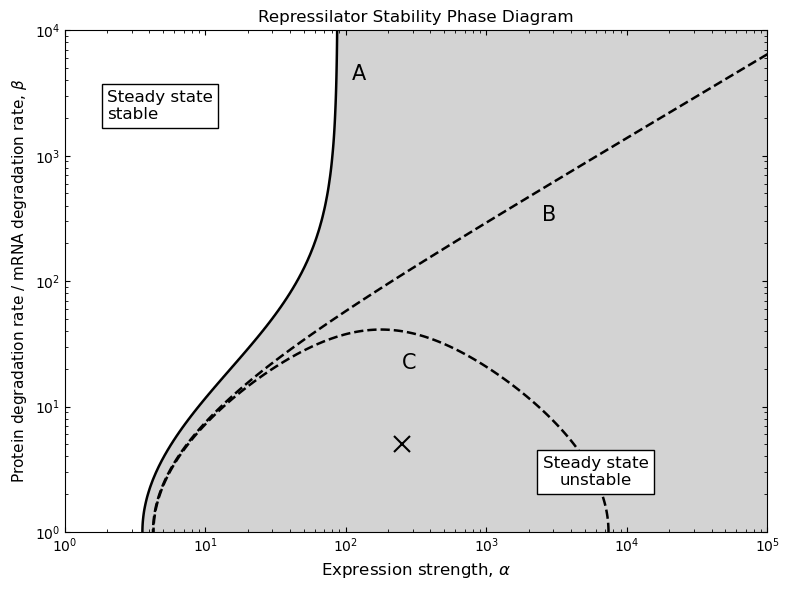

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# Parameter ranges
alpha_values = np.logspace(0, 5, 240)
beta_values = np.logspace(0, 4, 200)

# Name, Hill coefficient, basal-expression fraction, line style
cases = [
    ("A", 2.1, 0.0, "-"),
    ("B", 2.0, 0.0, "--"),
    ("C", 2.0, 1e-3, "--"),
]


# Find the symmetric equilibrium
def find_equilibrium(alpha, n, leak_fraction):
    alpha0 = leak_fraction * alpha

    def equation(p):
        return p - alpha / (1 + p**n) - alpha0

    return brentq(equation, 0.0, alpha + alpha0)


# Jacobian of the six equations at the symmetric equilibrium
def jacobian(q, beta):
    # Variable order:
    # [m_lacI, m_tetR, m_cI, p_lacI, p_tetR, p_cI]
    #
    # q is the magnitude of the repression-function slope.
    # The last three rows come from dp_i/dt = -beta*(p_i - m_i).

    return np.array([
        [-1,    0,    0,     0,     0,    -q],
        [ 0,   -1,    0,    -q,     0,     0],
        [ 0,    0,   -1,     0,    -q,     0],
        [beta,  0,    0, -beta,     0,     0],
        [ 0, beta,    0,     0, -beta,     0],
        [ 0,    0, beta,     0,     0, -beta],
    ], dtype=float)


# Calculate stability across the parameter plane
stability_fields = {}

for name, n, leak_fraction, line_style in cases:
    field = np.zeros((len(beta_values), len(alpha_values)))

    for col, alpha in enumerate(alpha_values):
        p_star = find_equilibrium(alpha, n, leak_fraction)

        q = (
            alpha * n * p_star**(n - 1)
            / (1 + p_star**n)**2
        )

        for row, beta in enumerate(beta_values):
            J = jacobian(q, beta)
            eigenvalues = np.linalg.eigvals(J)

            # Positive: unstable; negative: stable
            field[row, col] = np.max(eigenvalues.real)

    stability_fields[name] = field

# Draw the phase diagram
fig, ax = plt.subplots(figsize=(8, 6))

# Shade the unstable region for case A
ax.contourf(
    alpha_values,
    beta_values,
    stability_fields["A"],
    levels=[-10, 0, 10],
    colors=["white", "lightgray"],
)

# Draw the stability boundaries
for name, n, leak_fraction, line_style in cases:
    ax.contour(
        alpha_values,
        beta_values,
        stability_fields[name],
        levels=[0],
        colors="black",
        linestyles=line_style,
        linewidths=1.8,
    )

# Boundary labels
ax.text(110, 4000, "A", fontsize=15)
ax.text(2500, 300, "B", fontsize=15)
ax.text(250, 20, "C", fontsize=15)

# These region labels refer to case A
ax.text(
    2, 2500,
    "Steady state\nstable",
    fontsize=12,
    va="center",
    bbox=dict(facecolor="white", edgecolor="black"),
)

ax.text(
    6000, 3,
    "Steady state\nunstable",
    fontsize=12,
    ha="center",
    va="center",
    bbox=dict(facecolor="white", edgecolor="black"),
)

# Example parameter choice
ax.plot(
    250, 5,
    marker="x",
    color="black",
    markersize=11,
    markeredgewidth=1.5,
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1, 1e5)
ax.set_ylim(1, 1e4)

ax.set_xlabel(r"Expression strength, $\alpha$", fontsize=12)
ax.set_ylabel(
    r"Protein degradation rate / mRNA degradation rate, $\beta$",
    fontsize=11,
)
ax.set_title("Repressilator Stability Phase Diagram")
ax.tick_params(which="both", direction="in", top=True, right=True)

plt.tight_layout()
plt.show()